Replace H by f(x) = 1/(1 + e−ηx) with η = 1000 and integrate with a stiff method to t = 30τa, starting
from (uL, uR, aL, aR) = (1, 0, 0, 0). Call a percept dominant when its rate exceeds the other’s by more than 1
2
, and
measure dominance durations between hand-overs, discarding the first three. (i) Plot uL, uR and aL, aR against time
for IL = IR = 1.3 and mark B and 1 − B on the adaptation panel. (ii) For IL = 1.3, 1.45, 1.6 at IR = 1.3 report
the mean TL and TR and compare with part (c). (iii) For w = 0.3 (below the window) report Tdom and compare
with τa ln[(w + I)/(g − w − I)]. Report durations to 3 significant digits and comment on the sign and size of the
discrepancies.


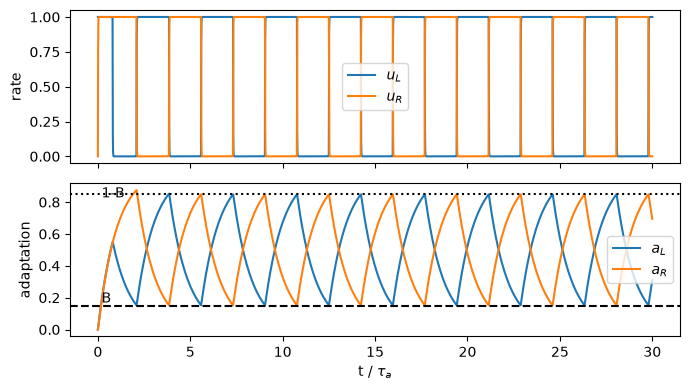

IL = 1.3: TL = 207.507, TR = 207.486(theoretical TL = 208.152, TR = 208.152)
IL = 1.45: TL = 197.138, TR = 160.093(theoretical TL = 197.067, TR = 159.496)
IL = 1.6: TL = 186.128, TR = 126.589(theoretical TL = 184.853, TR = 124.974)
w = 0.3: Tdom = 166.297, theoretical = 166.355


In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# parameters
w = 0.8
beta = 1.0
g = 2.0
tau = 120.0
eta = 1000.0

f = lambda x: 1 / (1 + np.exp(-np.clip(eta * x, -500, 500)))

def run(IL, IR, w = w):
    def rhs(t, y):
        uL, uR, aL, aR = y
        return [-uL + f(w * uL - beta * uR - g * aL + IL), 
                -uR + f(w * uR - beta * uL - g * aR + IR), 
                (-aL + uL) / tau, 
                (-aR + uR) / tau]
    t = np.arange(0, 30 * tau, 0.05)
    s = solve_ivp(rhs, (0, t[-1]), [1, 0, 0, 0], method="Radau", t_eval = t, rtol = 1e-8, atol = 1e-10)
    return s.t, s.y

def duration(t, y):
    d = y[0] - y[1]
    state = 1
    sw = []
    who = []
    for ti, di in zip(t, d):
        new = 1 if di > 0.5 else (-1 if di < -0.5 else state)
        if new != state:
            sw.append(ti)
            who.append(state) 
            state = new
    dur, who = np.diff(sw), np.array(who[1:])
    dur, who = dur[3:], who[3:]     # discard the first three dominance durations
    return dur[who == 1], dur[who == -1]

# (i)
t, y = run(1.3, 1.3)
B = (1.3 - beta) / g
fig, ax = plt.subplots(2, 1, sharex = True, figsize = (7, 4))
ax[0].plot(t/tau, y[0], label = "$u_L$")
ax[0].plot(t/tau, y[1], label = "$u_R$")
ax[0].set_ylabel("rate")
ax[0].legend()
ax[1].plot(t/tau, y[2], label = "$a_L$")
ax[1].plot(t/tau, y[3], label = "$a_R$")
ax[1].axhline(B, ls = "--", c = "k")
ax[1].axhline(1-B, ls = ":", c = "k")
ax[1].text(0.2, B + 0.02, "B")
ax[1].text(0.2, 1 - B - 0.02, "1-B")
ax[1].set_xlabel("t / $\\tau_a$")
ax[1].set_ylabel("adaptation")
ax[1].legend()
plt.tight_layout()
plt.show()

#(ii)
for IL in (1.3, 1.45, 1.6):
    TL, TR = duration(*run(IL, 1.3))
    BL, BR = (IL - beta) / g, (1.3 - beta) / g
    print(f"IL = {IL}: TL = {TL.mean():.3f}, TR = {TR.mean():.3f}" f"(theoretical TL = {tau * np.log((1 - BL) / BR):.3f}, TR = {tau * np.log((1 - BR) / BL):.3f})")

# (iii)
TL, TR = duration(*run(1.3, 1.3, w = 0.3))
T_th = tau * np.log((0.3 + 1.3) / (g - 0.3 - 1.3))
print(f"w = 0.3: Tdom = {np.mean(np.r_[TL, TR]):.3f}, theoretical = {T_th:.3f}")

